# Preprosesing data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Import data cần xử lý vào

Chúng ta sẽ làm việc với 3 file data chính là calendar, prices, sales.

Tập prices chứa các cột về giá cả của từng mặt hàng, sales chứa thông tin về doanh số từng ngày từ d_1 -> d_1968 với định dạng là ngang, calendar thì chứa thông tin ngày tháng thôi

In [ ]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

Hàm prep_calendar:

* Xoá cột không cần thiết.

* Chuyển cột d về số nguyên.

* Mã hóa các tên sự kiện thành số nguyên.

* Ép kiểu các cột số để tiết kiệm bộ nhớ.

In [ ]:
def prep_calendar(df):
    df = df.drop(["weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1


### 🧠 Hàm `downcast(df)` – Giảm kích thước DataFrame

Hàm này giúp **tối ưu bộ nhớ** bằng cách ép kiểu dữ liệu các cột sang dạng nhỏ nhất phù hợp, mà vẫn giữ nguyên giá trị.

---

#### ✅ Mục đích:
- Giảm dung lượng bộ nhớ RAM khi làm việc với dữ liệu lớn.
- Tăng hiệu suất xử lý.

---

#### 🔍 Cách hoạt động:

1. **Lặp qua từng cột trong DataFrame**.
2. Nếu là **kiểu số nguyên (`int`)**:
   - Ép kiểu thành `int8`, `int16`, `int32`, hoặc `int64` tùy theo giá trị min/max.
3. Nếu là **kiểu số thực (`float`)**:
   - Ép kiểu thành `float32` nếu phù hợp.
   - Tránh dùng `float16` (vì không tương thích với Parquet).
4. Nếu là **chuỗi (`object`)**:
   - Nếu cột tên là `date` → chuyển thành `datetime`.
   - Các cột khác → chuyển thành `category`.


In [ ]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

In [ ]:
# Calculate memory usage before running the function
memory_before = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

sales = downcast(sales)
prices = downcast(prices)
calendar = downcast(calendar)

memory_after = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

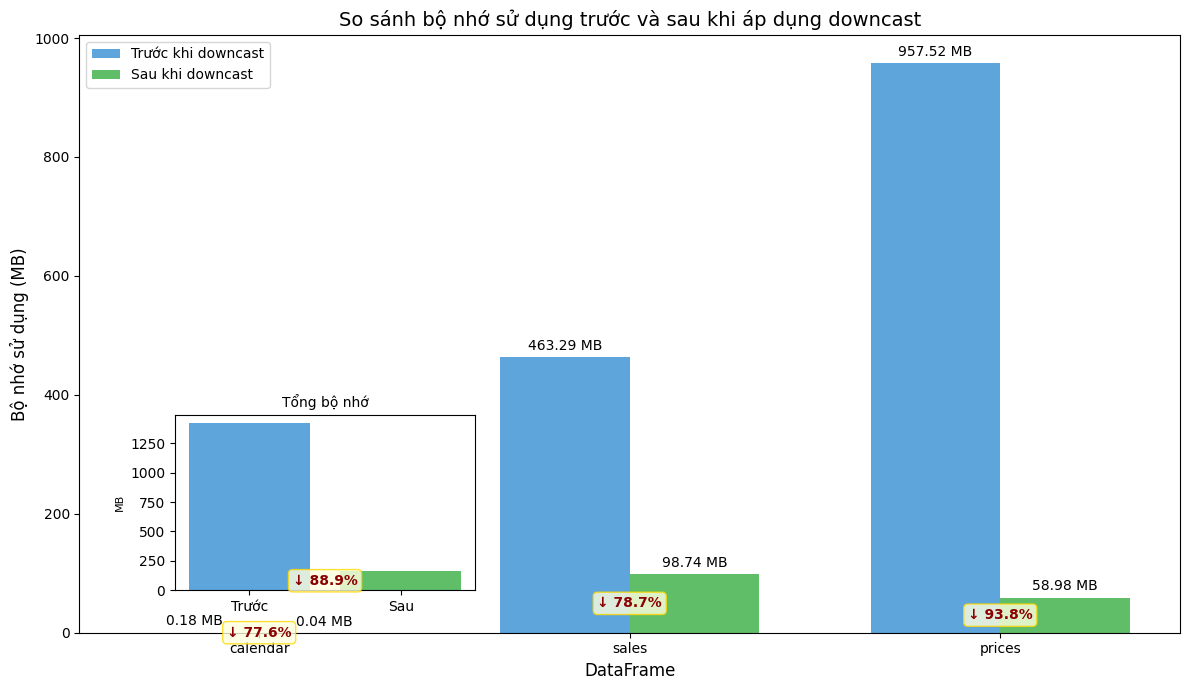


Thông tin chi tiết về bộ nhớ sử dụng:
DataFrame  Trước (MB)      Sau (MB)        Giảm (MB)       Giảm (%)  
----------------------------------------------------------------------
calendar   0.18            0.04            0.14            77.6      
sales      463.29          98.74           364.56          78.7      
prices     957.52          58.98           898.54          93.8      
----------------------------------------------------------------------
TỔNG       1420.99         157.76          1263.23         88.9      


In [ ]:
def plot_memory_comparison(memory_before, memory_after):
    """
    Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
    Parameters:
    -----------
    memory_before : dict
        Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
    memory_after : dict
        Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
    """
    
    # Lấy tên của các DataFrame
    df_names = list(memory_before.keys())
    
    # Tính toán giá trị bộ nhớ ở MB
    before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
    after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
    # Tính phần trăm giảm bộ nhớ
    reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
    # Thiết lập vị trí của các cột
    x = np.arange(len(df_names))
    width = 0.35
    
    # Tạo biểu đồ
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
    rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
    # Thêm nhãn, tiêu đề và các thông tin khác
    ax.set_xlabel('DataFrame', fontsize=12)
    ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
    ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(df_names)
    ax.legend()
    
    # Thêm giá trị lên mỗi cột
    def add_labels(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f} MB',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  # 3 points vertical offset
                         textcoords="offset points",
                         ha='center', va='bottom')
    
    add_labels(rects1)
    add_labels(rects2)
    
    # Thêm phần trăm giảm bộ nhớ
    for i, pct in enumerate(reduction_pct):
        ax.annotate(f'↓ {pct:.1f}%',
                    xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
                    xytext=(0, 0),
                    textcoords="offset points",
                    ha='center', va='center',
                    color='darkred',
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.tight_layout()
    
    # Thêm biểu đồ tổng hợp
    ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
    total_before = sum(before_mb)
    total_after = sum(after_mb)
    total_reduction = (total_before - total_after) / total_before * 100
    
    ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
    ax2.set_title('Tổng bộ nhớ', fontsize=10)
    ax2.set_ylabel('MB', fontsize=8)
    ax2.annotate(f'↓ {total_reduction:.1f}%', 
                xy=(0.5, min(total_before, total_after) / 2),
                xytext=(0, 0),
                textcoords="offset points",
                ha='center', va='center',
                color='darkred',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.show()
    
    # In thông tin chi tiết
    print("\nThông tin chi tiết về bộ nhớ sử dụng:")
    print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
    print("-" * 70)
    
    for i, name in enumerate(df_names):
        reduced = memory_before[name] - memory_after[name]
        reduced_mb = reduced / (1024 * 1024)
        print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
    print("-" * 70)
    total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
    print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# Sử dụng hàm
plot_memory_comparison(memory_before, memory_after)

### 💾 Vì sao nên lưu file dưới dạng `.parquet` thay vì `.csv`?

- **Dung lượng nhỏ hơn** nhờ hỗ trợ nén và lưu trữ theo cột.
- **Tốc độ đọc/ghi nhanh hơn** nhiều so với `.csv`.
- **Giữ nguyên kiểu dữ liệu** (dtype), không cần xử lý lại sau khi load.
- **Linh hoạt khi xử lý**, chỉ cần đọc các cột cần thiết.


In [ ]:
calendar.to_parquet('done_cal.parquet')
sales.to_parquet('done_sales.parquet')
prices.to_parquet('done_prices.parquet')

In [ ]:
calendar

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1964,2016-06-15,11620,5,6,2016,1965,1,1,0,1,1
1965,2016-06-16,11620,6,6,2016,1966,1,1,0,0,0
1966,2016-06-17,11620,7,6,2016,1967,1,1,0,0,0
1967,2016-06-18,11621,1,6,2016,1968,1,1,0,0,0


Sau mỗi lần dùng và tạo ra df mà không cần sử dụng nữa thì ta dùng del và gc.collect() để xóa bộ nhớ

In [ ]:
import gc
del calendar, prices, sales
gc.collect()

5631

# Ở đây xử lí dữ liệu disasater để thêm một cột dữ liệu cho df gốc.

Quy tắc là thêm một cột disaster_severity_flag nhằm biểu thị mức độ nghiệm trọng của thiên tai ảnh hưởng tới doanh thu của hàng hóa, nếu doanh thu ít mà trong ngày đó xảy ra thiên tai thì chứng tỏ thiên tai có ảnh hưởng nghiêm trọng tới doanh thu, doanh thu càng thấp thì flag có giá trị càng cao và ngược lại, ở đây nhóm em đề xuất sử dụng thang đo là 15( có thể thử nghiệm thêm nhiều thang đo tùy thôi, test nhiều thang để biết thang nào có hiệu suất cao nhất)

In [14]:
disater = pd.read_csv('../data/us_disasters_m5.csv')

def prep_disater(disater):
    done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
    # Chuyển đổi kiểu datetime
    done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
    done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
    # Thay thế giá trị thiếu trong incident_end_date
    done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
        done_dis['incident_begin_date'] + pd.Timedelta(days=1)
    )
    
    done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
    done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)
    
    return done_dis

done_dis = prep_disater(disater)

print(done_dis['incident_type'].unique())
print(done_dis['state'].unique())

from sklearn.preprocessing import LabelEncoder

# B1: Gắn tên bang từ state_id để khớp done_dis
label_encoder = LabelEncoder()
done_dis['state'] = label_encoder.fit_transform(done_dis['state'])+1

done_dis.to_parquet('../data/done_dis.parquet')

['Fire' 'Snow' 'Tsunami' 'Severe Storm(s)' 'Other' 'Earthquake' 'Flood']
['TX' 'WI' 'CA']


In [15]:
import gc
del done_dis, disater
gc.collect()

0

In [16]:
calendar = pd.read_parquet('done_cal.parquet')

prices = pd.read_parquet('done_prices.parquet')

sales = pd.read_parquet('done_sales.parquet')

done_dis = pd.read_parquet('../data/done_dis.parquet')

In [ ]:
from sklearn.model_selection import train_test_split

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
    return df

df = prep_data(sales, 1000 - 28)
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')

4097.29


In [19]:
import gc
del calendar, prices, sales
gc.collect()

0

In [18]:
df['state_id'].unique()

array([1, 2, 3], dtype=int16)

In [17]:
done_dis['state'].unique()

array([2, 3, 1])

In [20]:
# B3: Khởi tạo cột disaster_type (ban đầu là None)
df['disaster_type'] = None

# B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
for _, row in done_dis.iterrows():
    mask = (
        (df['state_id'] == row['state']) &
        (df['date'] >= row['incident_begin_date']) &
        (df['date'] <= row['incident_end_date'])
    )
    df.loc[mask, 'disaster_type'] = row['incident_type']

# B5: Tính tổng doanh thu theo loại thảm họa
revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

# B6: Chuẩn hóa giá trị doanh thu để gán severity flag
# doanh thu càng thấp => mức độ ảnh hưởng càng nặng
rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
max_rank = rank.max()
severity_map = (rank / max_rank * 15).astype(int)  # chia thành 1–15

# B7: Gán cột flag theo loại thảm họa
df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0


In [21]:
print(df.columns)
print(df['disaster_severity_flag'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag'],
      dtype='object')
[ 0 15  3  7 11]


In [ ]:
df = df.drop(['disaster_type', 'date'],axis=1)
df.to_parquet('../data/train_val.parquet')
del df
gc.collect()
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')

0

In [26]:
df = pd.read_parquet('../data/train_val.parquet')
print(df.columns)
print(df['disaster_severity_flag'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'wday',
       'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA', 'snap_TX',
       'snap_WI', 'sell_price', 'disaster_severity_flag'],
      dtype='object')
[ 0 15  3  7 11]


In [27]:
print(len(df['disaster_severity_flag']))
grid_df = df[:][:27837370].dropna(subset=['demand'])
print(len(grid_df['disaster_severity_flag']))
del df
gc.collect()

28691090
27837370


30

In [28]:
grid_df

,id,item_id,store_id,state_id,dept_id,cat_id,d,demand,lag_t7,rolling_mean_lag7_w7,...,wday,month,year,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI,sell_price,disaster_severity_flag
0,HOBBIES_1_001_CA_1,1438,1,1,4,2,1029,0.0,0.0,1.000000,...,7,11,2013,1,1,0,0,0,8.26,0
1,HOBBIES_1_002_CA_1,1439,1,1,4,2,1029,0.0,1.0,0.142857,...,7,11,2013,1,1,0,0,0,3.97,0
2,HOBBIES_1_003_CA_1,1440,1,1,4,2,1029,0.0,0.0,0.000000,...,7,11,2013,1,1,0,0,0,NaN,0
3,HOBBIES_1_004_CA_1,1441,1,1,4,2,1029,3.0,0.0,1.142857,...,7,11,2013,1,1,0,0,0,4.64,0
4,HOBBIES_1_005_CA_1,1442,1,1,4,2,1029,1.0,1.0,0.428571,...,7,11,2013,1,1,0,0,0,3.08,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27837365,FOODS_3_823_WI_3,1433,10,3,3,1,1941,1.0,3.0,0.714286,...,2,5,2016,1,1,0,0,0,2.98,0
27837366,FOODS_3_824_WI_3,1434,10,3,3,1,1941,0.0,0.0,0.000000,...,2,5,2016,1,1,0,0,0,2.48,0
27837367,FOODS_3_825_WI_3,1435,10,3,3,1,1941,2.0,1.0,1.142857,...,2,5,2016,1,1,0,0,0,3.98,0
27837368,FOODS_3_826_WI_3,1436,10,3,3,1,1941,0.0,1.0,1.000000,...,2,5,2016,1,1,0,0,0,1.28,0


In [29]:
print(grid_df.columns)

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'wday',
       'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA', 'snap_TX',
       'snap_WI', 'sell_price', 'disaster_severity_flag'],
      dtype='object')


In [30]:
m = grid_df.id=='HOBBIES_1_288_CA_1'
sales_ts = grid_df.loc[m,'demand'].values
sales_ts

array([ 7.,  1.,  4.,  5.,  6.,  3.,  0.,  0.,  7.,  2.,  6.,  2.,  0.,
        5.,  4.,  3.,  0.,  0.,  0.,  0.,  0.,  0., 14.,  4.,  1.,  1.,
        1.,  5.,  6.,  1.,  6., 14.,  1.,  0.,  0.,  4.,  2.,  4.,  7.,
        3.,  1.,  2.,  3.,  6.,  4.,  2.,  0.,  1.,  4.,  1.,  2.,  1.,
       11.,  2.,  1.,  3.,  5., 10.,  2.,  4.,  7.,  2.,  0.,  0.,  0.,
        4.,  0.,  8., 12.,  0.,  0.,  0.,  5.,  2., 14.,  0.,  0.,  1.,
        2.,  7.,  1.,  8.,  4.,  3.,  2.,  0.,  2., 13.,  4.,  2.,  0.,
       13.,  4.,  5.,  0.,  9.,  6.,  6.,  3.,  2.,  6.,  0.,  0.,  6.,
        0.,  4.,  0.,  3., 11.,  0.,  0.,  2., 10.,  7.,  4.,  2.,  5.,
        0.,  1.,  3.,  1.,  4.,  2.,  3., 24.,  0.,  3., 24.,  2.,  4.,
       10.,  2., 22., 11.,  8.,  0.,  8.,  7.,  2.,  6.,  9.,  7.,  6.,
        7.,  1.,  8.,  0.,  2.,  5., 12.,  0.,  0.,  0., 14.,  3.,  2.,
       13.,  3.,  5.,  0.,  4., 15.,  0.,  0.,  0.,  0.,  0.,  5.,  0.,
        6.,  3.,  4.,  0.,  0.,  0.,  4.,  0.,  0.,  0.,  0.,  0

In [31]:
def gap_finder(ts):
    
    # this function finds gaps and calculates their length:
    ts = (~(ts > 0)).astype(int)

    for i, val in enumerate(ts):
        if val == 0: 
            continue
        else: 
            ts[i] += ts[i-1]
            ts[i-1] = -1
    return ts

def gap_counter(ts):
    
    # value_counts for gaps lengths
    
    counts = np.unique(ts, return_counts=True)
    return dict(zip(counts[0], counts[1]))

m = grid_df.id=='HOBBIES_1_288_CA_1'

sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))
sales_gaps

{-1: 410, 0: 375, 1: 67, 2: 35, 3: 14, 4: 4, 5: 3, 6: 2, 9: 1, 10: 1, 169: 1}

In [ ]:
# Lets try to build a synthetic series with gaps.
# We assume products have a constant chance of being sold on any particular day.
# So for every day we will flip an unfair coin with probability of sale equal to 'dates_with sale'/'all_dates'
# >>>This might be an oversimplistic assumption, a moving window might be used instead.

def synth_sales(gaps_dict, min_gap=1000):
    
    sum_sale_days = gaps_dict.get(0,0) # key '0' gives number of days with sales
    sum_days = sum(gaps_dict.values()) # sum of all keys - number of all days
    
    # Sum of days in gaps longer than minimum gap length:
    sum_gap_length = sum([k for k in [*sales_gaps.keys()] if k > min_gap])
    
    # Exlude all the gaps longer than min_gap_length from probability calculation:
    p = sum_sale_days/(sum_days-sum_gap_length)
    
    return np.random.binomial(1, p, sum(gaps_dict.values()))

synth_sales_gaps = gap_counter(gap_finder(synth_sales(sales_gaps)))
synth_sales_gaps

{-1: 527, 0: 162, 1: 94, 2: 57, 3: 28, 4: 20, 5: 11, 6: 7, 7: 4, 8: 2, 14: 1}

In [33]:
# As you can see we dont have results > 20. 
# To make sure this is a consistent result lets run simulation 1,000 times:
# >>>> n equal 1,000 might be an overshot for some ids.

n=1000

sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()
gap_length_prob

-1     537.718
 0     154.108
 1      91.086
 2      53.503
 3      31.534
 4      18.521
 5      10.927
 6       6.385
 7       3.755
 8       2.236
 9       1.323
 10      0.790
 11      0.481
 12      0.280
 13      0.145
 14      0.074
 15      0.052
 16      0.033
 17      0.021
 18      0.013
 19      0.007
 20      0.004
 21      0.001
 23      0.003
dtype: float64

In [34]:
# The shortest gap that has been seen in less than 5% of simulated series:
min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
min_gap_length

16

In [35]:
# Now we exclude the gaps longer than min_gap_length from 'probability of sale' calculation, 
# because we assume them to be non-random.
# Run the simulation recursively until the min_gap_length does not decrease:

n=1000
new_min_gap_length = 0

while new_min_gap_length != min_gap_length:
    
    if new_min_gap_length!=0: min_gap_length=new_min_gap_length

    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
    gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

    # Lets find the shortes gap that has been seen in les than 5% of simulated series:
    new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

min_gap_length

12

In [36]:
# Finally we need to make a feature 'out_of_stock' for the product:
m = grid_df.id=='HOBBIES_1_288_CA_1'
idx = grid_df.loc[m,'demand'].index

gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
gf = gf.replace(-1,np.nan).fillna(method='backfill') 
gf = gf > min_gap_length
gf

280         False
30770       False
61260       False
91750       False
122240      False
            ...  
27685200    False
27715690    False
27746180    False
27776670    False
27807160    False
Length: 913, dtype: bool

In [37]:
# Let calculate 'out-of-stock' for the first 30 ids:
grid_df['out_of_stock'] = 0

n=1000
prods = list(grid_df.id.unique())
gap_length_list = []

for prod_id in tqdm(prods):
    
    m = grid_df.id == prod_id
    idx = grid_df.loc[m,'demand'].index

    sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))

    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
    gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

    min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
    new_min_gap_length = 0
    
    while new_min_gap_length < min_gap_length:

        if new_min_gap_length!=0: min_gap_length=new_min_gap_length

        sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
        gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

        # Lets find the shortes gap that has been seen in les than 5% of simulated series:
        new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

    gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
    gf = gf.replace(-1,np.nan).fillna(method='backfill') 
    gf = gf > min_gap_length
    grid_df.loc[m,'out_of_stock'] = gf*1
    gap_length_list += [min_gap_length]

  1%|          | 178/30490 [04:51<13:47:17,  1.64s/it]


KeyboardInterrupt: 